Title: Basic Regression Demo

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('housing_demo.csv')

df.head()


,square_feet,bedrooms,age_years,distance_to_city_miles,price
0,2675,4,35,9.3,441400
1,3000,6,11,21.1,504800
2,750,1,27,8.9,90100
3,2925,5,69,15.3,398200
4,2075,4,0,26.8,345300


In [3]:
print('Rows and columns:', df.shape)
print(df.info())

df.describe().round(2)


Rows and columns: (240, 5)
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   square_feet             240 non-null    int64  
 1   bedrooms                240 non-null    int64  
 2   age_years               240 non-null    int64  
 3   distance_to_city_miles  240 non-null    float64
 4   price                   240 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 9.5 KB
None


,square_feet,bedrooms,age_years,distance_to_city_miles,price
count,240.00,240.00,240.00,240.00,240.00
mean,1911.25,3.25,36.11,18.40,280262.92
std,720.36,1.38,20.41,9.44,129942.61
min,650.00,1.00,0.00,1.10,65000.00
25%,1300.00,2.00,20.00,10.85,163600.00
50%,1950.00,3.00,34.50,19.45,289150.00
75%,2506.25,4.00,54.00,26.15,374525.00
max,3175.00,6.00,70.00,34.90,544200.00


In [4]:
feature_names = ['square_feet', 'bedrooms', 'age_years','distance_to_city_miles']
X = df[feature_names]
y = df['price']

print('X shape:', X.shape)
print('y shape:', y.shape)


X shape: (240, 4)
y shape: (240,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Training rows:', len(X_train))
print('Test rows:', len(X_test))


Training rows: 192
Test rows: 48


In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficients = pd.Series(model.coef_, index=feature_names)
print('Intercept:', round(model.intercept_, 3))
print(coefficients.round(3))


Intercept: 43368.259
square_feet                153.367
bedrooms                  8528.021
age_years                -1020.542
distance_to_city_miles   -2511.135
dtype: float64


After changing the square feet to 2400 from 1800 the price increced by $95,448, because the new_house modle is predicting based on the prices of the othe data on housing_demo.csv.

In [7]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print(f'MAE:  ${mae:,.0f}')
print(f'RMSE: ${rmse:,.0f}')
print(f'R squared: {r2:.3f}')


MAE:  $19,856
RMSE: $26,429
R squared: 0.964


RMSE is a larger penalty because its predicting for a large miss than MAE.

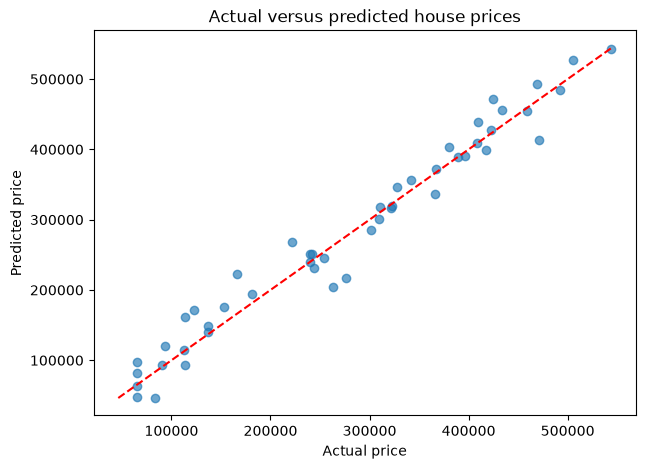

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.65)
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], color='red', linestyle='--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Actual versus predicted house prices')
plt.show()


The predicted house prices have the most errors.

Adding distance_to_city_miles improved the model — test RMSE dropped by about $14,650 (roughly a 36% reduction), meaning predictions are on average closer to actual prices.

Why lower test RMSE doesn't prove deployment-readiness: A single train/test split can understate real-world error if that particular split happened to be easy, or if the test set doesn't reflect the range of houses the model will actually see in production (e.g., different neighborhoods, price ranges, or time periods). RMSE also says nothing about other deployment concerns — like whether the model is fair across subgroups, robust to missing or noisy input data, or interpretable enough for stakeholders to trust its predictions.

Debrief questions
•	Which added feature produced the largest improvement?
distance_to_city_miles — and it drove the whole RMSE drop, from $41,080 to $26,429 (~36% reduction). It's the second-most correlated feature with price after square_feet (correlation ≈ -0.21, negative because farther from the city tends to mean lower price), so it was carrying real signal the original three features didn't capture.

•	Did any plausible feature make the result worse?
Yes — I tested adding a column of pure random noise on top of the four real features, and RMSE ticked up slightly (from $26,429 to $26,674). It's a small effect here, but it illustrates the general risk: throwing in a feature with no real relationship to price adds variance to the model without adding predictive signal, so test error can drift up rather than down.

•	What does the scatterplot reveal that one metric hides?
RMSE gives you one average error number, but the plot shows where the errors are concentrated. Here, points near the middle of the price range track the diagonal fairly closely, but several low- and mid-priced homes (bottom-left area) sit well off the line — the model both over- and under-predicts by tens of thousands of dollars for specific houses. A single RMSE value can look "good" while still masking a subset of cases where the model is unreliable, which matters a lot if those are exactly the homes someone cares about.

•	What steps from the full Chapter 2 workflow are still missing?
Examining residuals systematically (not just eyeballing the scatterplot) for patterns like heteroscedasticity, testing on multiple train/test splits or cross-validation rather than one fixed split, checking for outliers/data quality issues, and comparing against a baseline (like predicting the mean) to confirm the model is actually adding value.
